In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.6/383.6 kB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.8/231.8 kB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.5/78.5 kB 7.4 MB/s eta 0:00:00


# ***in panama full feature dataset***

Using device: cuda
Train set shape (33630, 5, 17)
Testing set shape (14413, 5, 17)
Epoch 1/50, Loss: 0.026766
Epoch 2/50, Loss: 0.013639
Epoch 3/50, Loss: 0.011853
Epoch 4/50, Loss: 0.011132
Epoch 5/50, Loss: 0.010583
Epoch 6/50, Loss: 0.010098
Epoch 7/50, Loss: 0.010025
Epoch 8/50, Loss: 0.009929
Epoch 9/50, Loss: 0.009716
Epoch 10/50, Loss: 0.009418
Epoch 11/50, Loss: 0.009438
Epoch 12/50, Loss: 0.009342
Epoch 13/50, Loss: 0.009219
Epoch 14/50, Loss: 0.009123
Epoch 15/50, Loss: 0.008986
Epoch 16/50, Loss: 0.008971
Epoch 17/50, Loss: 0.008929
Epoch 18/50, Loss: 0.009012
Epoch 19/50, Loss: 0.008931
Epoch 20/50, Loss: 0.008921
Epoch 21/50, Loss: 0.008763
Epoch 22/50, Loss: 0.008606
Epoch 23/50, Loss: 0.008606
Epoch 24/50, Loss: 0.008531
Epoch 25/50, Loss: 0.008628
Epoch 26/50, Loss: 0.008616
Epoch 27/50, Loss: 0.008503
Epoch 28/50, Loss: 0.008486
Epoch 29/50, Loss: 0.008506
Epoch 30/50, Loss: 0.008355
Epoch 31/50, Loss: 0.008458
Epoch 32/50, Loss: 0.008442
Epoch 33/50, Loss: 0.008299
Ep

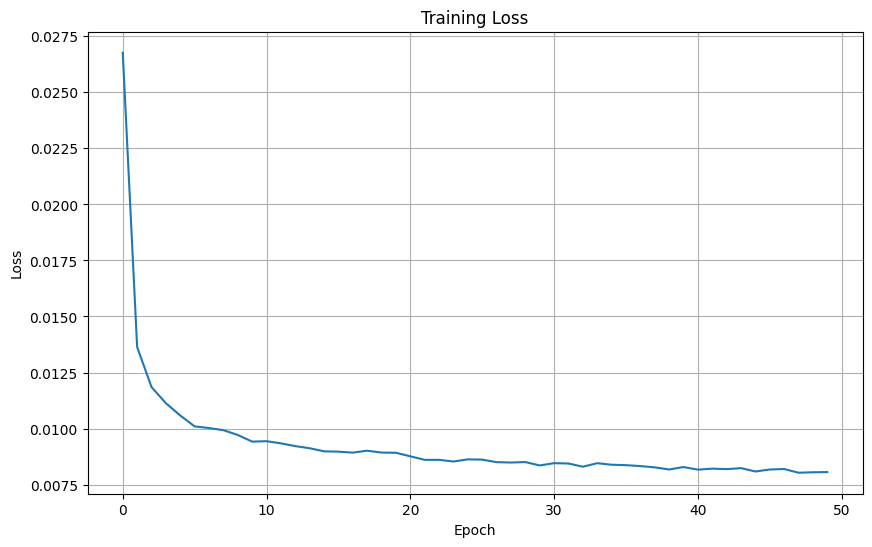

RMSE: 37.0763339748636
MAE: 25.836715698242188
MAPE: 2.184111624956131
MSE: 1374.654541015625
NRMSE: 3.04175431610082


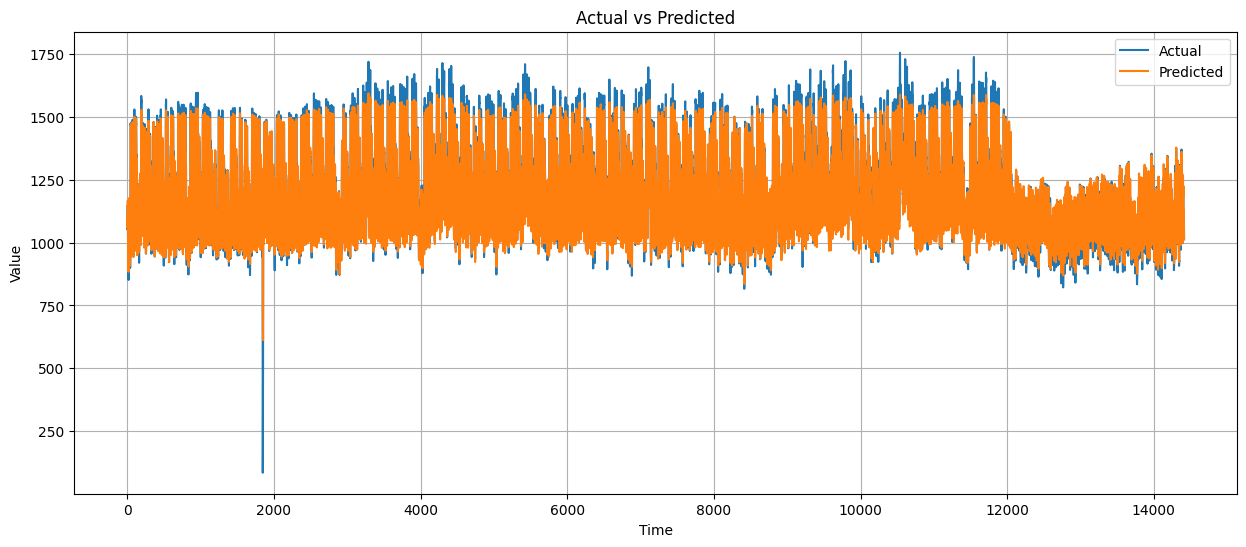

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check if CUDA is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Custom Dataset for Time Series
class PowerDataset(Dataset):
    def __init__(self, features, targets):
        self.features = features
        self.targets = targets

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return torch.FloatTensor(self.features[idx]), torch.FloatTensor(self.targets[idx])

# Dual Attention Mechanism
class DualAttention(nn.Module):
    def __init__(self, hidden_dim):
        super(DualAttention, self).__init__()
        # Temporal attention
        self.temporal_attn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, lstm_output):
        # lstm_output shape: [batch, seq_len, hidden_dim]

        # Temporal Attention (across time steps)
        temp_attn = self.temporal_attn(lstm_output)  # [batch, seq_len, 1]
        temp_attn = torch.softmax(temp_attn, dim=1)
        temp_context = torch.bmm(temp_attn.transpose(1, 2), lstm_output)  # [batch, 1, hidden_dim]

        # Use average pooling for feature attention
        feat_context = lstm_output.mean(dim=1)  # [batch, hidden_dim]

        # Combine both attention outputs
        combined_context = temp_context.squeeze(1) + feat_context

        return combined_context

# QLSTM Model with Attention
class DAQLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, num_layers=2, dropout=0.25):
        super(DAQLSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # LSTM layer
        self.lstm = nn.LSTM(
            input_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        # Attention mechanism
        self.attention = DualAttention(hidden_dim)

        # Dropout layer
        self.dropout = nn.Dropout(dropout)

        # Output layer
        self.output_layer = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # x shape: [batch, seq_len, input_dim]

        # Pass through LSTM
        lstm_out, _ = self.lstm(x)  # [batch, seq_len, hidden_dim]

        # Apply attention
        attn_out = self.attention(lstm_out)

        # Apply dropout
        attn_out = self.dropout(attn_out)

        # Output layer
        output = self.output_layer(attn_out)

        return output

# Quantile Loss Function
def quantile_loss(preds, targets, quantile=0.6):
    errors = targets - preds
    return torch.mean(torch.max(quantile * errors, (quantile - 1) * errors))

# Main execution
if __name__ == "__main__":
    # Load data
    df = pd.read_csv('/content/drive/MyDrive/thesis Final/Implementation/Panama Demand.csv')
    df.dropna(inplace=True)

    # Set target variable as 'nat_demand'
    df['target_variable'] = df['nat_demand']

    # Remove the datetime column for modeling
    if 'datetime' in df.columns:
        df = df.drop('datetime', axis=1)

    # Preprocess data
    s1 = MinMaxScaler(feature_range=(0, 1))
    Xs = s1.fit_transform(df)
    s2 = MinMaxScaler(feature_range=(0, 1))
    ys = s2.fit_transform(df[['target_variable']])

    window = 5
    X = []
    Y = []
    for i in range(window, len(Xs)):
        X.append(Xs[i-window:i, :])
        Y.append(ys[i])
    X, Y = np.array(X), np.array(Y)

    # Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, shuffle=False)
    print('Train set shape', X_train.shape)
    print('Testing set shape', X_test.shape)

    # Create datasets and dataloaders
    train_dataset = PowerDataset(X_train, y_train)
    test_dataset = PowerDataset(X_test, y_test)

    batch_size = 32
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    # Define model parameters
    input_dim = X_train.shape[2]  # Number of features
    hidden_dim = 32               # Hidden units
    num_layers = 2                # Number of LSTM layers
    dropout_rate = 0.25           # Dropout rate
    learning_rate = 0.01          # Learning rate
    num_epochs = 50               # Number of epochs
    quantile = 0.6                # Quantile for loss function

    # Initialize model
    model = DAQLSTM(
        input_dim=input_dim,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        dropout=dropout_rate
    ).to(device)

    # Optimizer
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Training loop
    model.train()
    train_losses = []

    for epoch in range(num_epochs):
        epoch_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            # Forward pass
            optimizer.zero_grad()
            outputs = model(X_batch)

            # Calculate loss
            loss = quantile_loss(outputs, y_batch, quantile)

            # Backward pass and optimize
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        # Average loss for the epoch
        epoch_loss /= len(train_loader)
        train_losses.append(epoch_loss)
        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.6f}')

    # Plot training loss
    plt.figure(figsize=(10, 6))
    plt.plot(train_losses)
    plt.title('Training Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True)
    plt.savefig('training_loss.png')
    plt.show()

    # Evaluation
    model.eval()
    predictions = []
    actuals = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            # Forward pass
            outputs = model(X_batch)

            # Store predictions and actuals
            predictions.extend(outputs.cpu().numpy())
            actuals.extend(y_batch.cpu().numpy())

    # Convert to numpy arrays and reshape
    predictions = np.array(predictions).reshape(-1, 1)
    actuals = np.array(actuals).reshape(-1, 1)

    # Inverse transform
    predictions = s2.inverse_transform(predictions)
    actuals = s2.inverse_transform(actuals)

    # Calculate metrics
    rmse = np.sqrt(mean_squared_error(actuals, predictions))
    mae = mean_absolute_error(actuals, predictions)
    mape = mean_absolute_percentage_error(actuals, predictions) * 100
    mse = mean_squared_error(actuals, predictions)
    nrmse = (rmse / np.mean(actuals)) * 100  # Changed to actuals for more standard NRMSE calculation

    print("RMSE:", rmse)
    print("MAE:", mae)
    print("MAPE:", mape)
    print("MSE:", mse)
    print("NRMSE:", nrmse)

    # Plot actual vs predicted
    plt.figure(figsize=(15, 6))
    plt.plot(actuals, label='Actual')
    plt.plot(predictions, label='Predicted')
    plt.title('Actual vs Predicted')
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.grid(True)
    plt.savefig('predictions.png')
    plt.show()

[I 2025-03-19 17:02:14,957] A new study created in memory with name: no-name-5e5f4191-1447-4277-b731-5474d1dc5e8b


Using device: cuda
Starting Panama Demand Forecasting with DAQLSTM
Loading and preprocessing data...
Missing values in dataset: 0
Dataset shape: (48048, 21)
Date range: 2015-01-03 01:00:00 to 2020-06-27 00:00:00
Train set shape: (33633, 20)
Validation set shape: (7207, 20)
Test set shape: (7208, 20)

Starting hyperparameter tuning with Optuna...
Epoch 1/30, Train Loss: 0.035463, Val Loss: 0.019713, Time: 7.93s
Epoch 2/30, Train Loss: 0.021617, Val Loss: 0.017981, Time: 7.93s
Epoch 3/30, Train Loss: 0.019691, Val Loss: 0.025179, Time: 7.87s
Epoch 4/30, Train Loss: 0.018463, Val Loss: 0.019447, Time: 7.87s
Epoch 5/30, Train Loss: 0.017802, Val Loss: 0.014175, Time: 7.86s
Epoch 6/30, Train Loss: 0.017308, Val Loss: 0.014199, Time: 7.78s
Epoch 7/30, Train Loss: 0.016759, Val Loss: 0.015521, Time: 7.85s
Epoch 8/30, Train Loss: 0.016332, Val Loss: 0.015745, Time: 7.82s
Epoch 9/30, Train Loss: 0.015700, Val Loss: 0.014690, Time: 7.82s
Epoch 10/30, Train Loss: 0.015098, Val Loss: 0.012646, Tim

[I 2025-03-19 17:05:23,752] Trial 0 finished with value: 0.008598518734797835 and parameters: {'hidden_dim': 64, 'num_layers': 1, 'dropout_rate': 0.1, 'learning_rate': 0.00014936568554617635, 'batch_size': 16, 'seq_length': 12, 'quantile': 0.5}. Best is trial 0 with value: 0.008598518734797835.


Epoch 24/30, Train Loss: 0.009870, Val Loss: 0.010407, Time: 7.88s
Early stopping triggered after epoch 24
Epoch 1/30, Train Loss: 0.054581, Val Loss: 0.045444, Time: 3.13s
Epoch 2/30, Train Loss: 0.039509, Val Loss: 0.021506, Time: 3.19s
Epoch 3/30, Train Loss: 0.022875, Val Loss: 0.028012, Time: 3.11s
Epoch 4/30, Train Loss: 0.020530, Val Loss: 0.033301, Time: 3.12s
Epoch 5/30, Train Loss: 0.019222, Val Loss: 0.017489, Time: 3.12s
Epoch 6/30, Train Loss: 0.018221, Val Loss: 0.016987, Time: 3.16s
Epoch 7/30, Train Loss: 0.016901, Val Loss: 0.023044, Time: 3.12s
Epoch 8/30, Train Loss: 0.016072, Val Loss: 0.013394, Time: 3.14s
Epoch 9/30, Train Loss: 0.015845, Val Loss: 0.023627, Time: 3.18s
Epoch 10/30, Train Loss: 0.015086, Val Loss: 0.017590, Time: 3.16s
Epoch 11/30, Train Loss: 0.014840, Val Loss: 0.012487, Time: 3.14s
Epoch 12/30, Train Loss: 0.014227, Val Loss: 0.013386, Time: 3.15s
Epoch 13/30, Train Loss: 0.013651, Val Loss: 0.017743, Time: 3.17s
Epoch 14/30, Train Loss: 0.0133

[I 2025-03-19 17:06:14,297] Trial 1 finished with value: 0.01248705803300254 and parameters: {'hidden_dim': 64, 'num_layers': 3, 'dropout_rate': 0.1, 'learning_rate': 0.0007523742884534858, 'batch_size': 64, 'seq_length': 72, 'quantile': 0.5}. Best is trial 0 with value: 0.008598518734797835.


...

[I 2025-03-19 17:33:37,757] Trial 19 finished with value: 0.01141853259621242 and parameters: {'hidden_dim': 128, 'num_layers': 4, 'dropout_rate': 0.1, 'learning_rate': 0.009285689078442084, 'batch_size': 16, 'seq_length': 24, 'quantile': 0.7}. Best is trial 17 with value: 0.004486715686248822.


Epoch 11/30, Train Loss: 0.012670, Val Loss: 0.027961, Time: 10.50s
Early stopping triggered after epoch 11

Best trial:
  Value (Validation Loss): 0.004486715686248822
  Params: 
    hidden_dim: 128
    num_layers: 3
    dropout_rate: 0.2
    learning_rate: 0.0013961496223920905
    batch_size: 16
    seq_length: 12
    quantile: 0.7

Training final model with best hyperparameters...


<ipython-input-5-cf621af88055>:364: ExperimentalWarning: plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study)


Sequence shapes after using window size 12:
  Train: (33621, 12, 20)
  Validation: (7195, 12, 20)
  Test: (7196, 12, 20)
Epoch 1/50, Train Loss: 0.022713, Val Loss: 0.014718, Time: 9.59s
Epoch 2/50, Train Loss: 0.015443, Val Loss: 0.012233, Time: 9.66s
Epoch 3/50, Train Loss: 0.013180, Val Loss: 0.016614, Time: 9.65s
Epoch 4/50, Train Loss: 0.011246, Val Loss: 0.011407, Time: 9.58s
Epoch 5/50, Train Loss: 0.009620, Val Loss: 0.007876, Time: 9.78s
Epoch 6/50, Train Loss: 0.008709, Val Loss: 0.008866, Time: 9.50s
Epoch 7/50, Train Loss: 0.007981, Val Loss: 0.008428, Time: 9.56s
Epoch 8/50, Train Loss: 0.007448, Val Loss: 0.009504, Time: 9.65s
Epoch 9/50, Train Loss: 0.007141, Val Loss: 0.009409, Time: 9.89s
Epoch 10/50, Train Loss: 0.006632, Val Loss: 0.005893, Time: 9.66s
Epoch 11/50, Train Loss: 0.006573, Val Loss: 0.007188, Time: 9.67s
Epoch 12/50, Train Loss: 0.006291, Val Loss: 0.005783, Time: 9.64s
Epoch 13/50, Train Loss: 0.006096, Val Loss: 0.006631, Time: 9.74s
Epoch 14/50, Trai

<Figure size 1000x600 with 0 Axes>

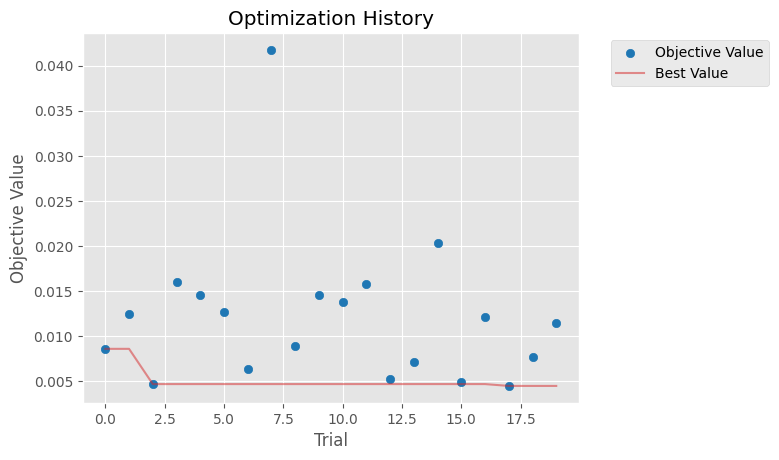

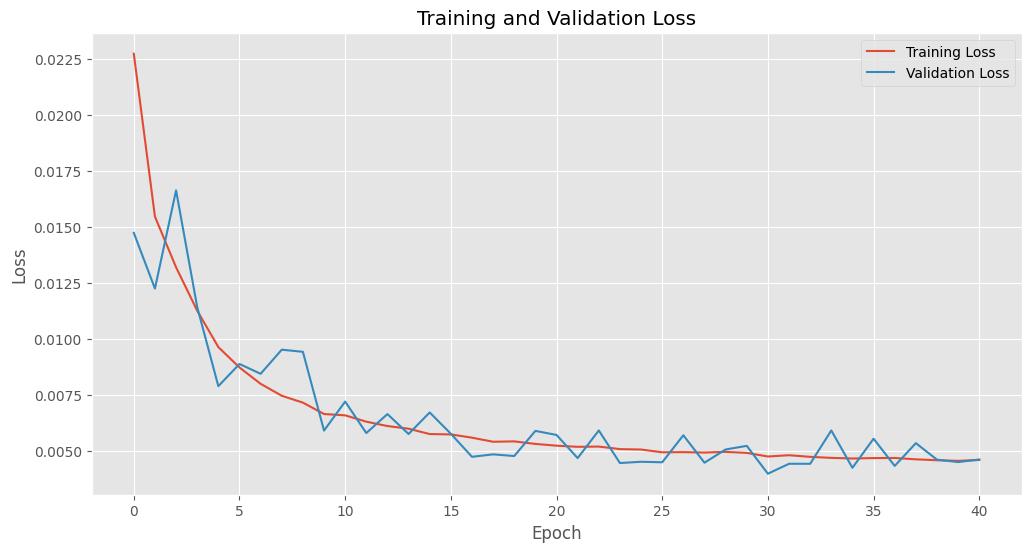


Evaluating model on test set...

Test Set Metrics:
RMSE: 37.6671
MAE: 25.9286
MAPE: 2.2233
MSE: 1418.8109
NRMSE: 3.1430


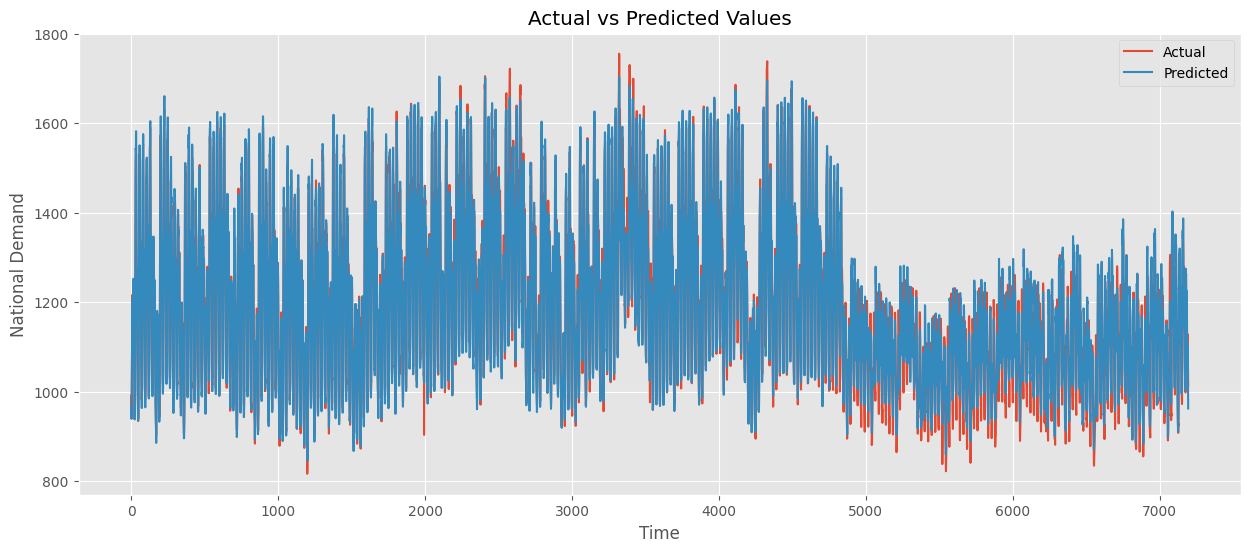

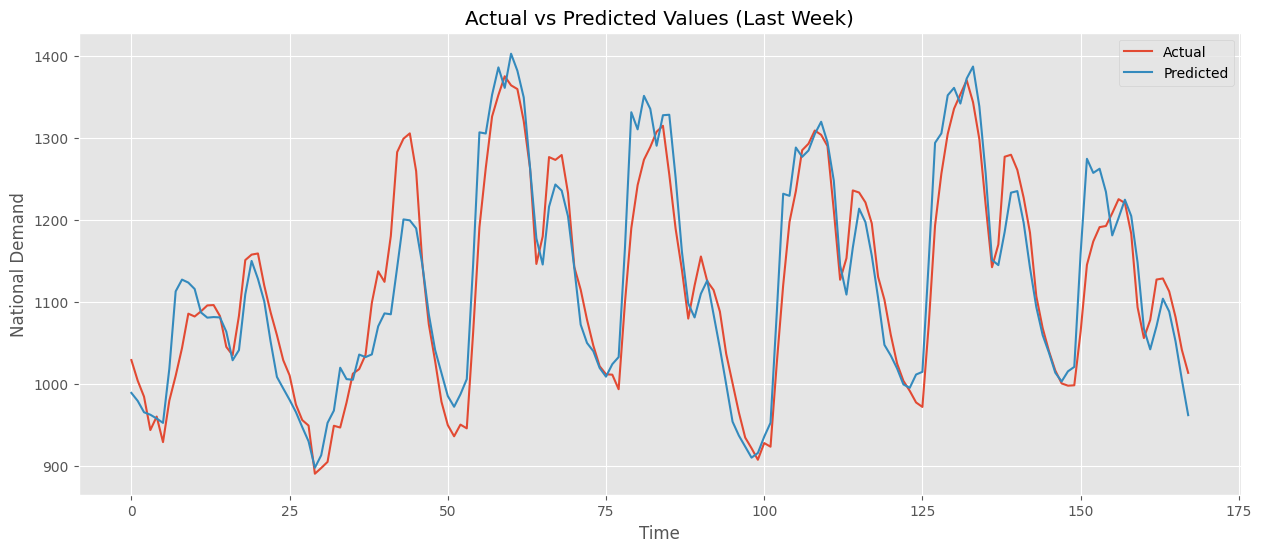

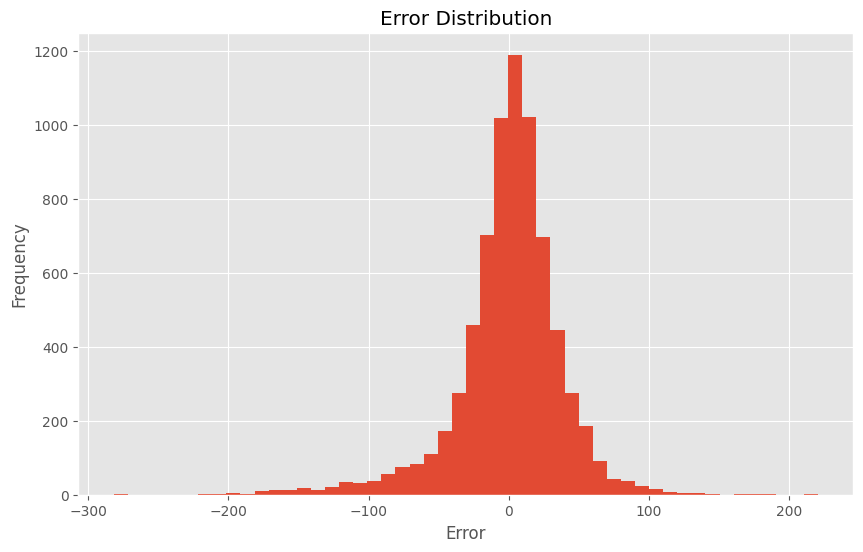


Completed Panama Demand Forecasting with DAQLSTM and Optuna Hyperparameter Tuning


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import optuna
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import os
import time
from datetime import datetime

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check if CUDA is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Custom Dataset for Time Series
class PowerDataset(Dataset):
    def __init__(self, features, targets):
        self.features = features
        self.targets = targets

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return torch.FloatTensor(self.features[idx]), torch.FloatTensor(self.targets[idx])

# Dual Attention Mechanism
class DualAttention(nn.Module):
    def __init__(self, hidden_dim):
        super(DualAttention, self).__init__()
        # Temporal attention
        self.temporal_attn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, lstm_output):
        # lstm_output shape: [batch, seq_len, hidden_dim]

        # Temporal Attention (across time steps)
        temp_attn = self.temporal_attn(lstm_output)  # [batch, seq_len, 1]
        temp_attn = torch.softmax(temp_attn, dim=1)
        temp_context = torch.bmm(temp_attn.transpose(1, 2), lstm_output)  # [batch, 1, hidden_dim]

        # Use average pooling for feature attention
        feat_context = lstm_output.mean(dim=1)  # [batch, hidden_dim]

        # Combine both attention outputs
        combined_context = temp_context.squeeze(1) + feat_context

        return combined_context

# QLSTM Model with Attention
class DAQLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, num_layers=2, dropout=0.25):
        super(DAQLSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # LSTM layer
        self.lstm = nn.LSTM(
            input_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        # Attention mechanism
        self.attention = DualAttention(hidden_dim)

        # Dropout layer
        self.dropout = nn.Dropout(dropout)

        # Output layer
        self.output_layer = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # x shape: [batch, seq_len, input_dim]

        # Pass through LSTM
        lstm_out, _ = self.lstm(x)  # [batch, seq_len, hidden_dim]

        # Apply attention
        attn_out = self.attention(lstm_out)

        # Apply dropout
        attn_out = self.dropout(attn_out)

        # Output layer
        output = self.output_layer(attn_out)

        return output

# Quantile Loss Function
def quantile_loss(preds, targets, quantile=0.6):
    errors = targets - preds
    return torch.mean(torch.max(quantile * errors, (quantile - 1) * errors))

# Function to create sequences for time series prediction
def create_sequences(X, y, seq_length):
    X_seq, y_seq = [], []
    for i in range(seq_length, len(X)):
        X_seq.append(X[i-seq_length:i, :])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

# Function to train the model with early stopping
def train_model(model, train_loader, val_loader, optimizer, num_epochs, patience=10, quantile=0.6):
    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_state = None

    for epoch in range(num_epochs):
        start_time = time.time()

        # Training phase
        model.train()
        train_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            # Forward pass
            optimizer.zero_grad()
            outputs = model(X_batch)

            # Calculate loss
            loss = quantile_loss(outputs, y_batch, quantile)

            # Backward pass and optimize
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        train_loss /= len(train_loader)
        train_losses.append(train_loss)

        # Validation phase
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)

                outputs = model(X_batch)
                loss = quantile_loss(outputs, y_batch, quantile)

                val_loss += loss.item()

        val_loss /= len(val_loader)
        val_losses.append(val_loss)

        epoch_time = time.time() - start_time

        # Print progress
        print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}, Time: {epoch_time:.2f}s')

        # Check for improvement
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
            best_model_state = model.state_dict().copy()
        else:
            epochs_no_improve += 1

        # Early stopping
        if epochs_no_improve >= patience:
            print(f'Early stopping triggered after epoch {epoch+1}')
            break

    # Load best model
    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return model, train_losses, val_losses, best_val_loss

# Function to evaluate the model
def evaluate_model(model, test_loader, scaler_y):
    model.eval()
    predictions = []
    actuals = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            # Forward pass
            outputs = model(X_batch)

            # Store predictions and actuals
            predictions.extend(outputs.cpu().numpy())
            actuals.extend(y_batch.cpu().numpy())

    # Convert to numpy arrays and reshape
    predictions = np.array(predictions).reshape(-1, 1)
    actuals = np.array(actuals).reshape(-1, 1)

    # Inverse transform to original scale
    predictions = scaler_y.inverse_transform(predictions)
    actuals = scaler_y.inverse_transform(actuals)

    # Calculate metrics
    rmse = np.sqrt(mean_squared_error(actuals, predictions))
    mae = mean_absolute_error(actuals, predictions)
    mape = mean_absolute_percentage_error(actuals, predictions) * 100
    mse = mean_squared_error(actuals, predictions)
    nrmse = (rmse / np.mean(actuals)) * 100

    metrics = {
        'RMSE': rmse,
        'MAE': mae,
        'MAPE': mape,
        'MSE': mse,
        'NRMSE': nrmse
    }

    return predictions, actuals, metrics

# Optuna objective function for hyperparameter tuning
def objective(trial, X_train, y_train, X_val, y_val, input_dim):
    # Define hyperparameters to be tuned
    hidden_dim = trial.suggest_categorical('hidden_dim', [32, 64, 128, 256])
    num_layers = trial.suggest_int('num_layers', 1, 4)
    dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5, step=0.1)
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-1, log=True)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64, 128])
    seq_length = trial.suggest_categorical('seq_length', [12, 24, 48, 72])
    quantile = trial.suggest_float('quantile', 0.5, 0.7, step=0.05)

    # Create sequences
    X_train_seq, y_train_seq = create_sequences(X_train, y_train, seq_length)
    X_val_seq, y_val_seq = create_sequences(X_val, y_val, seq_length)

    # Create datasets and dataloaders
    train_dataset = PowerDataset(X_train_seq, y_train_seq)
    val_dataset = PowerDataset(X_val_seq, y_val_seq)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    # Initialize model
    model = DAQLSTM(
        input_dim=input_dim,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        dropout=dropout_rate
    ).to(device)

    # Optimizer
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Train with early stopping
    _, _, _, best_val_loss = train_model(
        model,
        train_loader,
        val_loader,
        optimizer,
        num_epochs=30,  # Limit epochs for faster tuning
        patience=5,
        quantile=quantile
    )

    return best_val_loss

# Main execution
if __name__ == "__main__":
    print("Starting Panama Demand Forecasting with DAQLSTM")

    # Load data
    print("Loading and preprocessing data...")
    df = pd.read_csv('/content/drive/MyDrive/thesis Final/Implementation/Panama Demand.csv')

    # Check for missing values
    missing_values = df.isnull().sum().sum()
    print(f"Missing values in dataset: {missing_values}")

    # Handle missing values if any
    if missing_values > 0:
        print("Filling missing values...")
        df = df.fillna(method='ffill').fillna(method='bfill')  # Forward and backward fill

    # Convert datetime and extract features
    df['datetime'] = pd.to_datetime(df['datetime'])
    df['hour'] = df['datetime'].dt.hour
    df['day_of_week'] = df['datetime'].dt.dayofweek
    df['month'] = df['datetime'].dt.month
    df['day_of_year'] = df['datetime'].dt.dayofyear

    # Print dataset info
    print(f"Dataset shape: {df.shape}")
    print(f"Date range: {df['datetime'].min()} to {df['datetime'].max()}")

    # Define target and drop datetime column
    target_column = 'nat_demand'
    features_df = df.drop(['datetime'], axis=1)

    # Scale data
    scaler_X = MinMaxScaler(feature_range=(0, 1))
    scaler_y = MinMaxScaler(feature_range=(0, 1))

    # Scale features
    X_scaled = scaler_X.fit_transform(features_df)

    # Scale target (only nat_demand)
    y_scaled = scaler_y.fit_transform(df[[target_column]])

    # Split data into train, validation, and test sets (70%, 15%, 15%)
    train_size = int(0.7 * len(X_scaled))
    val_size = int(0.15 * len(X_scaled))

    X_train = X_scaled[:train_size]
    X_val = X_scaled[train_size:train_size+val_size]
    X_test = X_scaled[train_size+val_size:]

    y_train = y_scaled[:train_size]
    y_val = y_scaled[train_size:train_size+val_size]
    y_test = y_scaled[train_size+val_size:]

    print(f"Train set shape: {X_train.shape}")
    print(f"Validation set shape: {X_val.shape}")
    print(f"Test set shape: {X_test.shape}")

    # Input dimension for the model
    input_dim = X_train.shape[1]

    # Hyperparameter tuning with Optuna
    print("\nStarting hyperparameter tuning with Optuna...")

    # Create a study object with Optuna
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))

    # Run hyperparameter optimization
    study.optimize(
        lambda trial: objective(trial, X_train, y_train, X_val, y_val, input_dim),
        n_trials=20,  # Adjust based on computational resources
        timeout=3600  # 1 hour timeout
    )

    # Get best trial and hyperparameters
    best_trial = study.best_trial
    best_params = best_trial.params

    print("\nBest trial:")
    print(f"  Value (Validation Loss): {best_trial.value}")
    print("  Params: ")
    for key, value in best_params.items():
        print(f"    {key}: {value}")

    # Plot optimization history
    plt.figure(figsize=(10, 6))
    optuna.visualization.matplotlib.plot_optimization_history(study)
    plt.title('Optimization History')
    plt.savefig('optuna_history.png')

    # Training with the best hyperparameters
    print("\nTraining final model with best hyperparameters...")

    # Get best hyperparameters
    best_hidden_dim = best_params['hidden_dim']
    best_num_layers = best_params['num_layers']
    best_dropout_rate = best_params['dropout_rate']
    best_learning_rate = best_params['learning_rate']
    best_batch_size = best_params['batch_size']
    best_seq_length = best_params['seq_length']
    best_quantile = best_params['quantile']

    # Create sequences with best sequence length
    X_train_seq, y_train_seq = create_sequences(X_train, y_train, best_seq_length)
    X_val_seq, y_val_seq = create_sequences(X_val, y_val, best_seq_length)
    X_test_seq, y_test_seq = create_sequences(X_test, y_test, best_seq_length)

    print(f"Sequence shapes after using window size {best_seq_length}:")
    print(f"  Train: {X_train_seq.shape}")
    print(f"  Validation: {X_val_seq.shape}")
    print(f"  Test: {X_test_seq.shape}")

    # Create datasets and dataloaders
    train_dataset = PowerDataset(X_train_seq, y_train_seq)
    val_dataset = PowerDataset(X_val_seq, y_val_seq)
    test_dataset = PowerDataset(X_test_seq, y_test_seq)

    train_loader = DataLoader(train_dataset, batch_size=best_batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=best_batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=best_batch_size, shuffle=False)

    # Initialize final model with best hyperparameters
    final_model = DAQLSTM(
        input_dim=input_dim,
        hidden_dim=best_hidden_dim,
        num_layers=best_num_layers,
        dropout=best_dropout_rate
    ).to(device)

    # Optimizer
    optimizer = optim.Adam(final_model.parameters(), lr=best_learning_rate)

    # Train final model
    final_model, train_losses, val_losses, _ = train_model(
        final_model,
        train_loader,
        val_loader,
        optimizer,
        num_epochs=50,
        patience=10,
        quantile=best_quantile
    )

    # Save the model
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    model_filename = f"daqlstm_panama_demand_{timestamp}.pth"

    torch.save({
        'model_state_dict': final_model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'hyperparameters': best_params,
        'scaler_X': scaler_X,
        'scaler_y': scaler_y
    }, model_filename)

    print(f"Model saved to {model_filename}")

    # Plot training and validation loss
    plt.figure(figsize=(12, 6))
    plt.plot(train_losses, label='Training Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.savefig(f'training_loss_{timestamp}.png')
    plt.show()

    # Evaluate on test set
    print("\nEvaluating model on test set...")
    predictions, actuals, metrics = evaluate_model(final_model, test_loader, scaler_y)

    # Print metrics
    print("\nTest Set Metrics:")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

    # Plot actual vs predicted values for the test set
    plt.figure(figsize=(15, 6))
    plt.plot(actuals, label='Actual')
    plt.plot(predictions, label='Predicted')
    plt.title('Actual vs Predicted Values')
    plt.xlabel('Time')
    plt.ylabel('National Demand')
    plt.legend()
    plt.grid(True)
    plt.savefig(f'predictions_{timestamp}.png')
    plt.show()

    # Plot a subset of the predictions (last week) for better visibility
    plt.figure(figsize=(15, 6))
    subset_size = min(168, len(predictions))  # 168 hours = 1 week
    plt.plot(actuals[-subset_size:], label='Actual')
    plt.plot(predictions[-subset_size:], label='Predicted')
    plt.title('Actual vs Predicted Values (Last Week)')
    plt.xlabel('Time')
    plt.ylabel('National Demand')
    plt.legend()
    plt.grid(True)
    plt.savefig(f'predictions_lastweek_{timestamp}.png')
    plt.show()

    # Plot error distribution
    errors = actuals.flatten() - predictions.flatten()
    plt.figure(figsize=(10, 6))
    plt.hist(errors, bins=50)
    plt.title('Error Distribution')
    plt.xlabel('Error')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.savefig(f'error_distribution_{timestamp}.png')
    plt.show()

    print("\nCompleted Panama Demand Forecasting with DAQLSTM and Optuna Hyperparameter Tuning")

[I 2025-03-02 14:03:48,069] A new study created in memory with name: no-name-c1b642af-e3c4-4dfc-8c30-fddf7bab77c1


Using device: cuda


[I 2025-03-02 14:04:04,849] Trial 0 finished with value: 0.01839373644063438 and parameters: {'hidden_dim': 58, 'num_layers': 1, 'dropout_rate': 0.33279170666370206, 'learning_rate': 0.0008759843434054603, 'batch_size': 128, 'bidirectional': True}. Best is trial 0 with value: 0.01839373644063438.
[I 2025-03-02 14:04:31,185] Trial 1 finished with value: 0.017074987700168232 and parameters: {'hidden_dim': 94, 'num_layers': 2, 'dropout_rate': 0.10951699266016646, 'learning_rate': 0.0053940473258660155, 'batch_size': 64, 'bidirectional': False}. Best is trial 1 with value: 0.017074987700168232.
[I 2025-03-02 14:05:47,126] Trial 2 finished with value: 0.021305916428347647 and parameters: {'hidden_dim': 256, 'num_layers': 2, 'dropout_rate': 0.15025748100632208, 'learning_rate': 0.009063045745469279, 'batch_size': 32, 'bidirectional': True}. Best is trial 1 with value: 0.017074987700168232.
[I 2025-03-02 14:07:46,254] Trial 3 finished with value: 0.017084548983299908 and parameters: {'hidden_

Best hyperparameters: {'hidden_dim': 155, 'num_layers': 3, 'dropout_rate': 0.31778872002518443, 'learning_rate': 0.006081385415064595, 'batch_size': 16, 'bidirectional': True}
Epoch 1/100, Train Loss: 0.026145, Val Loss: 0.018768
Validation loss decreased (inf --> 0.018768). Saving model...
Epoch 2/100, Train Loss: 0.019965, Val Loss: 0.017547
Validation loss decreased (0.018768 --> 0.017547). Saving model...
Epoch 3/100, Train Loss: 0.018963, Val Loss: 0.025895
EarlyStopping counter: 1 out of 7
Epoch 4/100, Train Loss: 0.018250, Val Loss: 0.021187
EarlyStopping counter: 2 out of 7
Epoch 5/100, Train Loss: 0.017703, Val Loss: 0.022728
EarlyStopping counter: 3 out of 7
Epoch 6/100, Train Loss: 0.018590, Val Loss: 0.016573
Validation loss decreased (0.017547 --> 0.016573). Saving model...
Epoch 7/100, Train Loss: 0.017556, Val Loss: 0.018788
EarlyStopping counter: 1 out of 7
Epoch 8/100, Train Loss: 0.017120, Val Loss: 0.019542
EarlyStopping counter: 2 out of 7
Epoch 9/100, Train Loss: 0

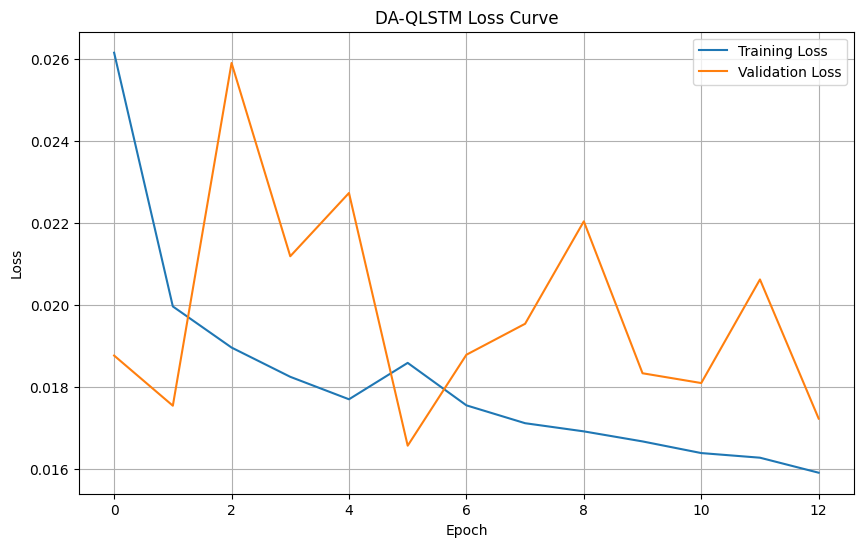

<ipython-input-6-d4f354a50eef>:543: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_save_path))


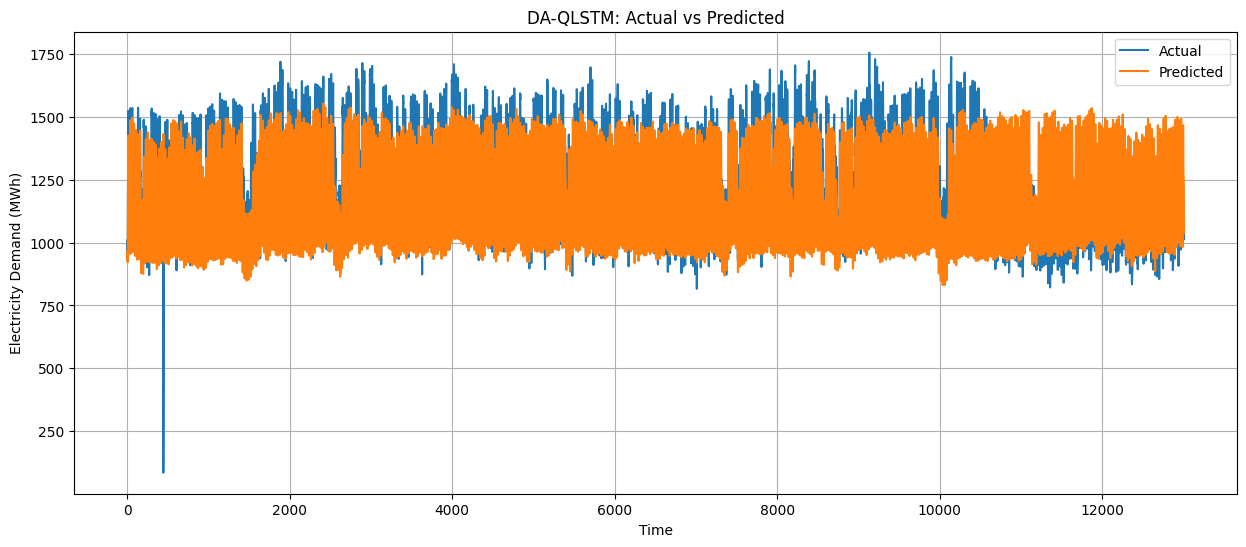


Evaluation Metrics:
MSE: 17558.5332
RMSE: 132.5086
MAE: 101.2925
NRMSE: 0.0794
MAPE: 8.6086


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import optuna
import math
import os
from datetime import datetime

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check if CUDA is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Custom Dataset for Time Series
class ElectricityDataset(Dataset):
    def __init__(self, features, targets, seq_length=24):
        self.features = features
        self.targets = targets
        self.seq_length = seq_length

    def __len__(self):
        return len(self.features) - self.seq_length

    def __getitem__(self, idx):
        x = self.features[idx:idx+self.seq_length]
        y = self.targets[idx+self.seq_length]
        return torch.FloatTensor(x), torch.FloatTensor([y])

# Dual Attention Mechanism
class DualAttention(nn.Module):
    def __init__(self, hidden_dim):
        super(DualAttention, self).__init__()
        # Temporal attention
        self.temporal_attn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )

        # Feature attention
        self.feature_attn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, lstm_output):
      # lstm_output shape: [batch, seq_len, hidden_dim]

      # Temporal Attention (across time steps)
      temp_attn = self.temporal_attn(lstm_output)  # [batch, seq_len, 1]
      temp_attn = torch.softmax(temp_attn, dim=1)
      temp_context = torch.bmm(temp_attn.transpose(1, 2), lstm_output)  # [batch, 1, hidden_dim]

      # For feature attention, just use a simpler approach:
      # Use average pooling along sequence dimension
      feat_context = lstm_output.mean(dim=1)  # [batch, hidden_dim]

      # We'll still return attention weights for consistency
      feat_attn = torch.ones_like(temp_attn)  # [batch, seq_len, 1]

      # Combine both attention outputs
      combined_context = temp_context.squeeze(1) + feat_context

      return combined_context, temp_attn, feat_attn

# Quantile LSTM Model with Dual Attention
class DAQLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim, dropout=0.2, bidirectional=False, quantiles=[0.1, 0.5, 0.9]):
        super(DAQLSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.quantiles = quantiles

        # LSTM layer
        self.lstm = nn.LSTM(
            input_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        # Adjust hidden dimension if bidirectional
        self.effective_hidden_dim = hidden_dim * 2 if bidirectional else hidden_dim

        # Dual Attention mechanism
        self.attention = DualAttention(self.effective_hidden_dim)

        # Separate output layers for each quantile
        self.quantile_outputs = nn.ModuleList([
            nn.Linear(self.effective_hidden_dim, output_dim) for _ in quantiles
        ])

        # Dropout layer
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x shape: [batch, seq_len, input_dim]
        batch_size = x.size(0)

        # Pass through LSTM
        lstm_out, _ = self.lstm(x)  # [batch, seq_len, hidden_dim]

        # Apply attention
        attn_out, temp_attn, feat_attn = self.attention(lstm_out)

        # Apply dropout
        attn_out = self.dropout(attn_out)

        # Pass through the output layers for each quantile
        quantile_preds = []
        for q_out in self.quantile_outputs:
            quantile_preds.append(q_out(attn_out))

        return quantile_preds, temp_attn, feat_attn

# Quantile Loss Function
def quantile_loss(preds, targets, quantiles):
    losses = []
    for i, q in enumerate(quantiles):
        errors = targets - preds[i]
        losses.append(torch.max(q * errors, (q - 1) * errors).mean())
    return torch.stack(losses).mean()

# Custom early stopping
class EarlyStopping:
    def __init__(self, patience=7, min_delta=0, verbose=False):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = float('inf')

    def __call__(self, val_loss, model, model_path='best_model.pth'):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model, model_path)
        elif score < self.best_score + self.min_delta:
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model, model_path)
            self.counter = 0

    def save_checkpoint(self, val_loss, model, path):
        if self.verbose:
            print(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model...')
        torch.save(model.state_dict(), path)
        self.val_loss_min = val_loss

# Evaluation metrics
def calculate_metrics(y_true, y_pred):
    # MSE
    mse = mean_squared_error(y_true, y_pred)
    # RMSE
    rmse = np.sqrt(mse)
    # MAE
    mae = mean_absolute_error(y_true, y_pred)
    # NRMSE (Normalized RMSE)
    nrmse = rmse / (np.max(y_true) - np.min(y_true))
    # MAPE (Mean Absolute Percentage Error)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    return {
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'NRMSE': nrmse,
        'MAPE': mape
    }

# Function to prepare data
def prepare_data(df, train_years, val_year, seq_length=24):
    # Extract datetime from index and create a year column
    df['year'] = pd.to_datetime(df.index).year

    # Split data based on years
    train_data = df[df['year'].isin(train_years)].drop('year', axis=1)
    val_data = df[df['year'] == val_year].drop('year', axis=1)
    test_data = df[~df['year'].isin(train_years + [val_year])].drop('year', axis=1)

    # Separate features and target
    target_col = 'nat_demand'
    train_features = train_data.drop(target_col, axis=1).values
    train_target = train_data[target_col].values
    val_features = val_data.drop(target_col, axis=1).values
    val_target = val_data[target_col].values
    test_features = test_data.drop(target_col, axis=1).values
    test_target = test_data[target_col].values

    # Scale features
    feature_scaler = MinMaxScaler()
    train_features_scaled = feature_scaler.fit_transform(train_features)
    val_features_scaled = feature_scaler.transform(val_features)
    test_features_scaled = feature_scaler.transform(test_features)

    # Scale target
    target_scaler = MinMaxScaler()
    train_target_scaled = target_scaler.fit_transform(train_target.reshape(-1, 1)).flatten()
    val_target_scaled = target_scaler.transform(val_target.reshape(-1, 1)).flatten()
    test_target_scaled = target_scaler.transform(test_target.reshape(-1, 1)).flatten()

    # Create datasets
    train_dataset = ElectricityDataset(train_features_scaled, train_target_scaled, seq_length)
    val_dataset = ElectricityDataset(val_features_scaled, val_target_scaled, seq_length)
    test_dataset = ElectricityDataset(test_features_scaled, test_target_scaled, seq_length)

    return train_dataset, val_dataset, test_dataset, target_scaler, feature_scaler

# Function to plot training and validation loss
def plot_losses(train_losses, val_losses, title="Loss Curve", save_path=None):
    plt.figure(figsize=(10, 6))
    plt.plot(train_losses, label='Training Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    if save_path:
        plt.savefig(save_path)

    plt.show()

# Function to plot actual vs predicted values
def plot_predictions(y_true, y_pred, title="Actual vs Predicted", save_path=None):
    plt.figure(figsize=(15, 6))
    plt.plot(y_true, label='Actual')
    plt.plot(y_pred, label='Predicted')
    plt.title(title)
    plt.xlabel('Time')
    plt.ylabel('Electricity Demand (MWh)')
    plt.legend()
    plt.grid(True)

    if save_path:
        plt.savefig(save_path)

    plt.show()

# Optuna objective function for hyperparameter tuning
def objective(trial, df, train_years, val_year, seq_length=24):
    # Hyperparameters to optimize
    hidden_dim = trial.suggest_int('hidden_dim', 32, 256)
    num_layers = trial.suggest_int('num_layers', 1, 3)
    dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5)
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64, 128])
    bidirectional = trial.suggest_categorical('bidirectional', [True, False])
    quantiles = [0.1, 0.5, 0.9]  # Fixed quantiles

    # Prepare data
    train_dataset, val_dataset, _, _, _ = prepare_data(
        df, train_years, val_year, seq_length
    )

    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    # Calculate input dimension based on dataset features
    input_dim = train_dataset.features.shape[1]

    # Initialize model
    model = DAQLSTM(
        input_dim=input_dim,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        output_dim=1,
        dropout=dropout_rate,
        bidirectional=bidirectional,
        quantiles=quantiles
    ).to(device)

    # Optimizer
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Train the model for a few epochs to evaluate its performance
    num_epochs = 10
    best_val_loss = float('inf')

    for epoch in range(num_epochs):
        # Training
        model.train()
        train_loss = 0.0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()

            # Forward pass
            quantile_preds, _, _ = model(X_batch)

            # Calculate loss
            loss = quantile_loss(quantile_preds, y_batch, quantiles)

            # Backward pass
            loss.backward()

            # Update weights
            optimizer.step()

            train_loss += loss.item()

        # Validation
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)

                # Forward pass
                quantile_preds, _, _ = model(X_batch)

                # Calculate loss
                loss = quantile_loss(quantile_preds, y_batch, quantiles)

                val_loss += loss.item()

        # Average loss
        train_loss /= len(train_loader)
        val_loss /= len(val_loader)

        if val_loss < best_val_loss:
            best_val_loss = val_loss

    return best_val_loss

# Function to train the model
def train_model(model, train_loader, val_loader, optimizer, num_epochs, quantiles, model_save_path, patience=7):
    # Initialize early stopping
    early_stopping = EarlyStopping(patience=patience, verbose=True)

    # Initialize lists to store losses
    train_losses = []
    val_losses = []

    # Loop through epochs
    for epoch in range(num_epochs):
        # Training
        model.train()
        train_loss = 0.0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()

            # Forward pass
            quantile_preds, _, _ = model(X_batch)

            # Calculate loss
            loss = quantile_loss(quantile_preds, y_batch, quantiles)

            # Backward pass
            loss.backward()

            # Update weights
            optimizer.step()

            train_loss += loss.item()

        # Average training loss
        train_loss /= len(train_loader)
        train_losses.append(train_loss)

        # Validation
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)

                # Forward pass
                quantile_preds, _, _ = model(X_batch)

                # Calculate loss
                loss = quantile_loss(quantile_preds, y_batch, quantiles)

                val_loss += loss.item()

        # Average validation loss
        val_loss /= len(val_loader)
        val_losses.append(val_loss)

        # Print progress
        print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')

        # Check early stopping
        early_stopping(val_loss, model, model_save_path)
        if early_stopping.early_stop:
            print(f'Early stopping at epoch {epoch+1}')
            break

    return train_losses, val_losses

# Function to test the model
def test_model(model, test_loader, quantiles, target_scaler):
    model.eval()
    predictions = []
    actuals = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            # Forward pass
            quantile_preds, _, _ = model(X_batch)

            # Use median (0.5 quantile) for predictions
            median_idx = quantiles.index(0.5)
            median_preds = quantile_preds[median_idx]

            # Store predictions and actuals
            predictions.extend(median_preds.cpu().numpy().flatten())
            actuals.extend(y_batch.cpu().numpy().flatten())

    # Convert back to original scale
    predictions = target_scaler.inverse_transform(np.array(predictions).reshape(-1, 1)).flatten()
    actuals = target_scaler.inverse_transform(np.array(actuals).reshape(-1, 1)).flatten()

    return actuals, predictions

# Main function
def main():
    # Create results directory
    results_dir = 'results'
    os.makedirs(results_dir, exist_ok=True)

    # Set model name and timestamp
    model_name = 'DA-QLSTM'
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    model_dir = os.path.join(results_dir, f'{model_name}_{timestamp}')
    os.makedirs(model_dir, exist_ok=True)

    # File paths
    model_save_path = os.path.join(model_dir, 'best_model.pth')
    loss_plot_path = os.path.join(model_dir, 'loss_curve.png')
    pred_plot_path = os.path.join(model_dir, 'predictions.png')
    metrics_path = os.path.join(model_dir, 'metrics.txt')

    # Load data
    # You need to load your dataset here
    # For this example, we'll assume a dataframe named 'df' with the features mentioned

    df = pd.read_csv('/content/drive/MyDrive/thesis Final/Implementation/Panama Demand.csv', index_col='datetime', parse_dates=True)

    # Hyperparameter tuning with Optuna
    train_years = [2015, 2016, 2017]
    val_year = 2018
    seq_length = 24

    # Number of trials for Optuna
    n_trials = 50

    # Create an Optuna study
    study = optuna.create_study(direction='minimize')

    # Optimize
    study.optimize(lambda trial: objective(trial, df, train_years, val_year, seq_length), n_trials=n_trials)

    # Get best hyperparameters
    best_params = study.best_params

    # For this template, let's set some reasonable hyperparameters manually
    # In your real implementation, uncomment the Optuna code and comment out this section
    '''best_params = {
        'hidden_dim': 128,
        'num_layers': 2,
        'dropout_rate': 0.3,
        'learning_rate': 0.001,
        'batch_size': 64,
        'bidirectional': True
    }'''

    print(f"Best hyperparameters: {best_params}")

    # Prepare data
    train_dataset, val_dataset, test_dataset, target_scaler, feature_scaler = prepare_data(
        df, train_years, val_year, seq_length
    )

    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=best_params['batch_size'], shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=best_params['batch_size'], shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=best_params['batch_size'], shuffle=False)

    # Calculate input dimension
    input_dim = train_dataset.features.shape[1]

    # Set quantiles
    quantiles = [0.1, 0.5, 0.9]

    # Initialize model with best hyperparameters
    model = DAQLSTM(
        input_dim=input_dim,
        hidden_dim=best_params['hidden_dim'],
        num_layers=best_params['num_layers'],
        output_dim=1,
        dropout=best_params['dropout_rate'],
        bidirectional=best_params['bidirectional'],
        quantiles=quantiles
    ).to(device)

    # Optimizer
    optimizer = optim.Adam(model.parameters(), lr=best_params['learning_rate'])

    # Train the model
    num_epochs = 100  # Set a high number, early stopping will prevent overfitting
    train_losses, val_losses = train_model(
        model, train_loader, val_loader, optimizer, num_epochs,
        quantiles, model_save_path, patience=7
    )

    # Plot losses
    plot_losses(train_losses, val_losses, "DA-QLSTM Loss Curve", loss_plot_path)

    # Load best model for testing
    model.load_state_dict(torch.load(model_save_path))

    # Test the model
    actuals, predictions = test_model(model, test_loader, quantiles, target_scaler)

    # Plot predictions
    plot_predictions(actuals, predictions, "DA-QLSTM: Actual vs Predicted", pred_plot_path)

    # Calculate metrics
    metrics = calculate_metrics(actuals, predictions)

    # Print metrics
    print("\nEvaluation Metrics:")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

    # Save metrics to file
    with open(metrics_path, 'w') as f:
        f.write("Evaluation Metrics:\n")
        for metric, value in metrics.items():
            f.write(f"{metric}: {value:.4f}\n")

if __name__ == "__main__":
    main()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# ***DAQLSTM on actual dataset by original method***

Using device: cuda
Train set shape (33630, 5, 5)
Testing set shape (14413, 5, 5)
Epoch 1/50, Loss: 0.022628
Epoch 2/50, Loss: 0.012737
Epoch 3/50, Loss: 0.011662
Epoch 4/50, Loss: 0.010730
Epoch 5/50, Loss: 0.010518
Epoch 6/50, Loss: 0.010325
Epoch 7/50, Loss: 0.010035
Epoch 8/50, Loss: 0.009932
Epoch 9/50, Loss: 0.009774
Epoch 10/50, Loss: 0.009728
Epoch 11/50, Loss: 0.009385
Epoch 12/50, Loss: 0.009272
Epoch 13/50, Loss: 0.009073
Epoch 14/50, Loss: 0.008985
Epoch 15/50, Loss: 0.008986
Epoch 16/50, Loss: 0.008916
Epoch 17/50, Loss: 0.008931
Epoch 18/50, Loss: 0.008818
Epoch 19/50, Loss: 0.008750
Epoch 20/50, Loss: 0.008713
Epoch 21/50, Loss: 0.008724
Epoch 22/50, Loss: 0.008599
Epoch 23/50, Loss: 0.008497
Epoch 24/50, Loss: 0.008590
Epoch 25/50, Loss: 0.008387
Epoch 26/50, Loss: 0.008534
Epoch 27/50, Loss: 0.008544
Epoch 28/50, Loss: 0.008360
Epoch 29/50, Loss: 0.008305
Epoch 30/50, Loss: 0.008479
Epoch 31/50, Loss: 0.008318
Epoch 32/50, Loss: 0.008314
Epoch 33/50, Loss: 0.008283
Epoc

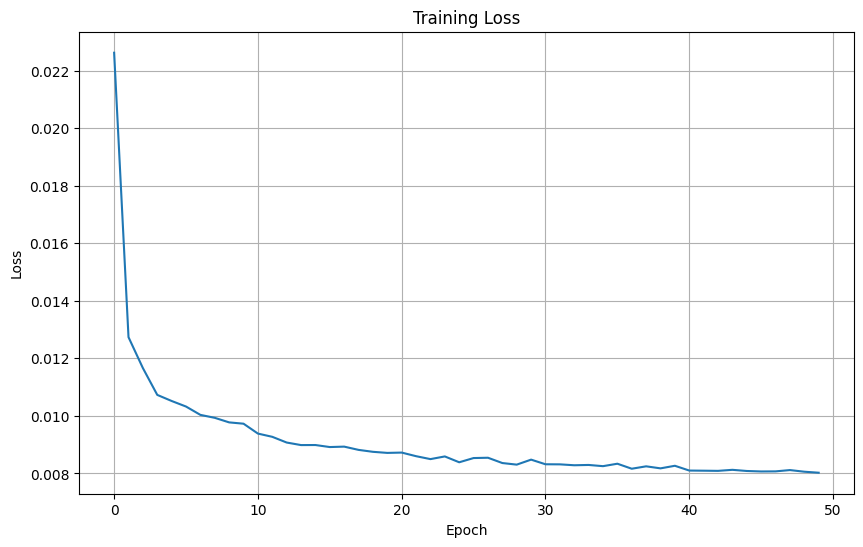

RMSE: 34.97725439761263
MAE: 24.452999114990234
MAPE: 2.147410623729229
MSE: 1223.4083251953125
NRMSE: 2.892848245638094


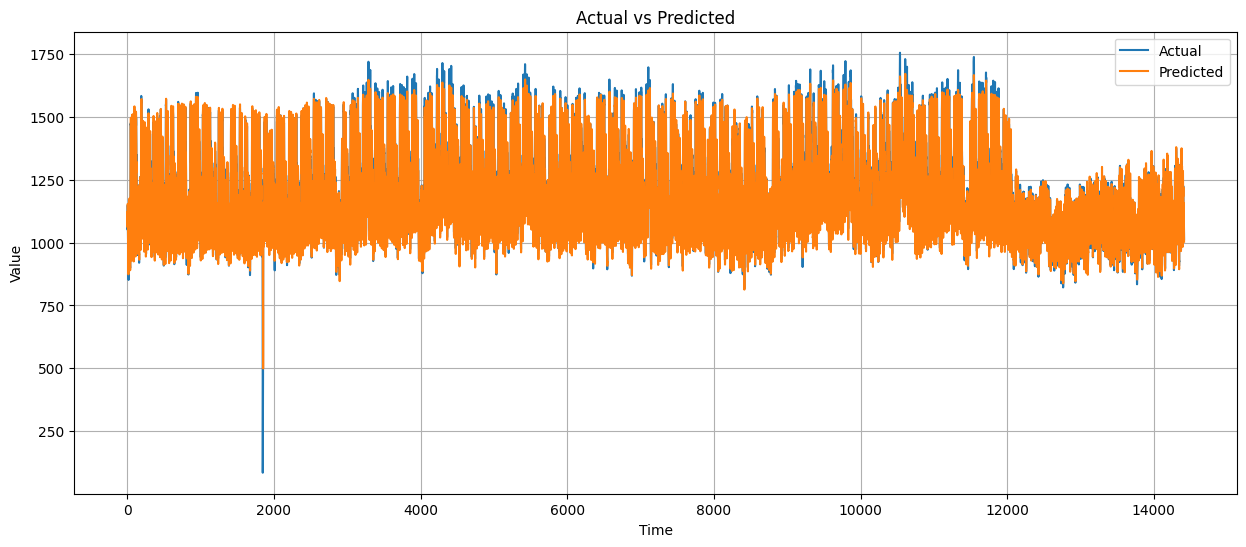

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check if CUDA is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Custom Dataset for Time Series
class PowerDataset(Dataset):
    def __init__(self, features, targets):
        self.features = features
        self.targets = targets

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return torch.FloatTensor(self.features[idx]), torch.FloatTensor(self.targets[idx])

# Dual Attention Mechanism
class DualAttention(nn.Module):
    def __init__(self, hidden_dim):
        super(DualAttention, self).__init__()
        # Temporal attention
        self.temporal_attn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, lstm_output):
        # lstm_output shape: [batch, seq_len, hidden_dim]

        # Temporal Attention (across time steps)
        temp_attn = self.temporal_attn(lstm_output)  # [batch, seq_len, 1]
        temp_attn = torch.softmax(temp_attn, dim=1)
        temp_context = torch.bmm(temp_attn.transpose(1, 2), lstm_output)  # [batch, 1, hidden_dim]

        # Use average pooling for feature attention
        feat_context = lstm_output.mean(dim=1)  # [batch, hidden_dim]

        # Combine both attention outputs
        combined_context = temp_context.squeeze(1) + feat_context

        return combined_context

# QLSTM Model with Attention
class DAQLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, num_layers=2, dropout=0.25):
        super(DAQLSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # LSTM layer
        self.lstm = nn.LSTM(
            input_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        # Attention mechanism
        self.attention = DualAttention(hidden_dim)

        # Dropout layer
        self.dropout = nn.Dropout(dropout)

        # Output layer
        self.output_layer = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # x shape: [batch, seq_len, input_dim]

        # Pass through LSTM
        lstm_out, _ = self.lstm(x)  # [batch, seq_len, hidden_dim]

        # Apply attention
        attn_out = self.attention(lstm_out)

        # Apply dropout
        attn_out = self.dropout(attn_out)

        # Output layer
        output = self.output_layer(attn_out)

        return output

# Quantile Loss Function
def quantile_loss(preds, targets, quantile=0.6):
    errors = targets - preds
    return torch.mean(torch.max(quantile * errors, (quantile - 1) * errors))

# Main execution
if __name__ == "__main__":
    # Load data
    df = pd.read_csv('/content/drive/MyDrive/thesis Final/Implementation/panama_dataset.csv')
    df.dropna(inplace=True)

    # Preprocess data
    s1 = MinMaxScaler(feature_range=(0, 1))
    Xs = s1.fit_transform(df)
    s2 = MinMaxScaler(feature_range=(0, 1))
    ys = s2.fit_transform(df[['target_variable']])

    window = 5
    X = []
    Y = []
    for i in range(window, len(Xs)):
        X.append(Xs[i-window:i, :])
        Y.append(ys[i])
    X, Y = np.array(X), np.array(Y)

    # Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, shuffle=False)
    print('Train set shape', X_train.shape)
    print('Testing set shape', X_test.shape)

    # Create datasets and dataloaders
    train_dataset = PowerDataset(X_train, y_train)
    test_dataset = PowerDataset(X_test, y_test)

    batch_size = 32
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    # Define model parameters
    input_dim = X_train.shape[2]  # Number of features
    hidden_dim = 32               # Hidden units
    num_layers = 2                # Number of LSTM layers
    dropout_rate = 0.25           # Dropout rate
    learning_rate = 0.01          # Learning rate
    num_epochs = 50               # Number of epochs
    quantile = 0.6                # Quantile for loss function

    # Initialize model
    model = DAQLSTM(
        input_dim=input_dim,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        dropout=dropout_rate
    ).to(device)

    # Optimizer
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Training loop
    model.train()
    train_losses = []

    for epoch in range(num_epochs):
        epoch_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            # Forward pass
            optimizer.zero_grad()
            outputs = model(X_batch)

            # Calculate loss
            loss = quantile_loss(outputs, y_batch, quantile)

            # Backward pass and optimize
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        # Average loss for the epoch
        epoch_loss /= len(train_loader)
        train_losses.append(epoch_loss)
        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.6f}')

    # Plot training loss
    plt.figure(figsize=(10, 6))
    plt.plot(train_losses)
    plt.title('Training Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True)
    plt.savefig('training_loss.png')
    plt.show()

    # Evaluation
    model.eval()
    predictions = []
    actuals = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            # Forward pass
            outputs = model(X_batch)

            # Store predictions and actuals
            predictions.extend(outputs.cpu().numpy())
            actuals.extend(y_batch.cpu().numpy())

    # Convert to numpy arrays and reshape
    predictions = np.array(predictions).reshape(-1, 1)
    actuals = np.array(actuals).reshape(-1, 1)

    # Inverse transform
    predictions = s2.inverse_transform(predictions)
    actuals = s2.inverse_transform(actuals)

    # Calculate metrics
    rmse = np.sqrt(mean_squared_error(actuals, predictions))
    mae = mean_absolute_error(actuals, predictions)
    mape = mean_absolute_percentage_error(actuals, predictions) * 100
    mse = mean_squared_error(actuals, predictions)
    nrmse = (rmse / np.mean(predictions)) * 100

    print("RMSE:", rmse)
    print("MAE:", mae)
    print("MAPE:", mape)
    print("MSE:", mse)
    print("NRMSE:", nrmse)

    # Plot actual vs predicted
    plt.figure(figsize=(15, 6))
    plt.plot(actuals, label='Actual')
    plt.plot(predictions, label='Predicted')
    plt.title('Actual vs Predicted')
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.grid(True)
    plt.savefig('predictions.png')
    plt.show()

# ***in albania dataset***

Using device: cuda
Starting Albania Load Forecasting with DAQLSTM
Loading and preprocessing data...


[I 2025-03-19 16:45:08,700] A new study created in memory with name: no-name-dac62b03-a719-4be0-96d1-4fa76f2a8fcb


Missing values in dataset: 0
Dataset shape: (35232, 14)
Date range: 2016-01-01 00:00:00 to 2020-01-07 23:00:00
Number of features: 12
Train set shape: (24676, 12)
Validation set shape: (5271, 12)
Test set shape: (5285, 12)

Starting hyperparameter tuning with Optuna...
Epoch 1/30, Train Loss: 0.045300, Val Loss: 0.039456, Time: 5.77s
Epoch 2/30, Train Loss: 0.031505, Val Loss: 0.030592, Time: 5.77s
Epoch 3/30, Train Loss: 0.027119, Val Loss: 0.026824, Time: 5.70s
Epoch 4/30, Train Loss: 0.023787, Val Loss: 0.026465, Time: 5.77s
Epoch 5/30, Train Loss: 0.022391, Val Loss: 0.030277, Time: 5.71s
Epoch 6/30, Train Loss: 0.021380, Val Loss: 0.029533, Time: 5.76s
Epoch 7/30, Train Loss: 0.020895, Val Loss: 0.024321, Time: 5.71s
Epoch 8/30, Train Loss: 0.020409, Val Loss: 0.026027, Time: 5.75s
Epoch 9/30, Train Loss: 0.020103, Val Loss: 0.031288, Time: 5.77s
Epoch 10/30, Train Loss: 0.019826, Val Loss: 0.027385, Time: 5.77s
Epoch 11/30, Train Loss: 0.019690, Val Loss: 0.024285, Time: 5.77s
Ep

[I 2025-03-19 16:46:40,987] Trial 0 finished with value: 0.02428477139447145 and parameters: {'hidden_dim': 64, 'num_layers': 1, 'dropout_rate': 0.1, 'learning_rate': 0.00014936568554617635, 'batch_size': 16, 'seq_length': 12, 'quantile': 0.5}. Best is trial 0 with value: 0.02428477139447145.


Epoch 16/30, Train Loss: 0.018883, Val Loss: 0.028672, Time: 5.79s
Early stopping triggered after epoch 16
Epoch 1/30, Train Loss: 0.081562, Val Loss: 0.080012, Time: 1.29s
Epoch 2/30, Train Loss: 0.056823, Val Loss: 0.033641, Time: 1.29s
Epoch 3/30, Train Loss: 0.033969, Val Loss: 0.034334, Time: 1.28s
Epoch 4/30, Train Loss: 0.031523, Val Loss: 0.034280, Time: 1.29s
Epoch 5/30, Train Loss: 0.029654, Val Loss: 0.034760, Time: 1.29s
Epoch 6/30, Train Loss: 0.028815, Val Loss: 0.036036, Time: 1.29s
Epoch 7/30, Train Loss: 0.027607, Val Loss: 0.033119, Time: 1.28s
Epoch 8/30, Train Loss: 0.026487, Val Loss: 0.024734, Time: 1.29s
Epoch 9/30, Train Loss: 0.024560, Val Loss: 0.031057, Time: 1.27s
Epoch 10/30, Train Loss: 0.023902, Val Loss: 0.039977, Time: 1.28s
Epoch 11/30, Train Loss: 0.023539, Val Loss: 0.032475, Time: 1.27s
Epoch 12/30, Train Loss: 0.022798, Val Loss: 0.032740, Time: 1.28s


...

[I 2025-03-19 16:59:28,163] Trial 19 finished with value: 0.022650214877524753 and parameters: {'hidden_dim': 128, 'num_layers': 2, 'dropout_rate': 0.4, 'learning_rate': 0.002278989815575708, 'batch_size': 64, 'seq_length': 24, 'quantile': 0.6}. Best is trial 11 with value: 0.018952365678521883.


Epoch 8/30, Train Loss: 0.018787, Val Loss: 0.026507, Time: 2.12s
Early stopping triggered after epoch 8

Best trial:
  Value (Validation Loss): 0.018952365678521883
  Params: 
    hidden_dim: 128
    num_layers: 2
    dropout_rate: 0.2
    learning_rate: 0.004412149541687046
    batch_size: 64
    seq_length: 12
    quantile: 0.7

Training final model with best hyperparameters...
Sequence shapes after using window size 12:
  Train: (24664, 12, 12)
  Validation: (5259, 12, 12)
  Test: (5273, 12, 12)


<ipython-input-4-72912bdb52d6>:362: ExperimentalWarning: plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study)


Epoch 1/100, Train Loss: 0.032953, Val Loss: 0.022331, Time: 2.10s
Epoch 2/100, Train Loss: 0.020075, Val Loss: 0.027624, Time: 2.03s
Epoch 3/100, Train Loss: 0.018413, Val Loss: 0.032926, Time: 2.03s
Epoch 4/100, Train Loss: 0.017363, Val Loss: 0.024071, Time: 2.02s
Epoch 5/100, Train Loss: 0.016941, Val Loss: 0.022421, Time: 2.02s
Epoch 6/100, Train Loss: 0.016630, Val Loss: 0.026717, Time: 2.04s
Epoch 7/100, Train Loss: 0.016356, Val Loss: 0.029579, Time: 2.05s
Epoch 8/100, Train Loss: 0.016173, Val Loss: 0.021395, Time: 2.02s
Epoch 9/100, Train Loss: 0.016256, Val Loss: 0.023278, Time: 2.02s
Epoch 10/100, Train Loss: 0.015536, Val Loss: 0.024116, Time: 2.02s
Epoch 11/100, Train Loss: 0.015636, Val Loss: 0.023408, Time: 2.02s
Epoch 12/100, Train Loss: 0.015309, Val Loss: 0.034958, Time: 2.06s
Epoch 13/100, Train Loss: 0.015261, Val Loss: 0.025534, Time: 2.05s
Epoch 14/100, Train Loss: 0.015137, Val Loss: 0.018502, Time: 2.01s
Epoch 15/100, Train Loss: 0.015019, Val Loss: 0.029690, T

<Figure size 1000x600 with 0 Axes>

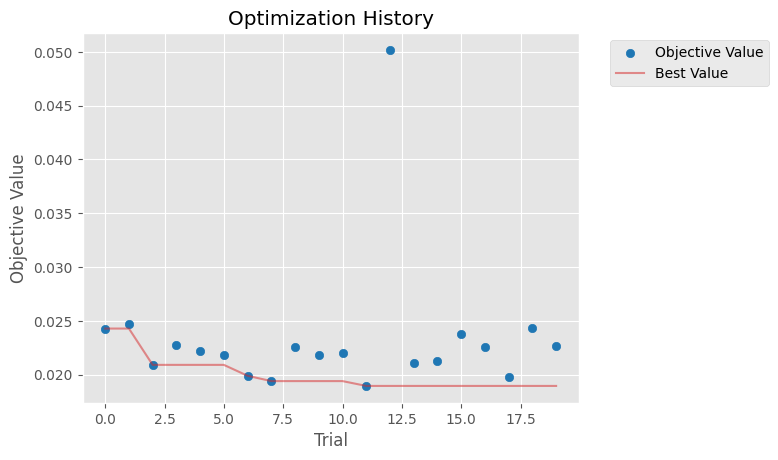

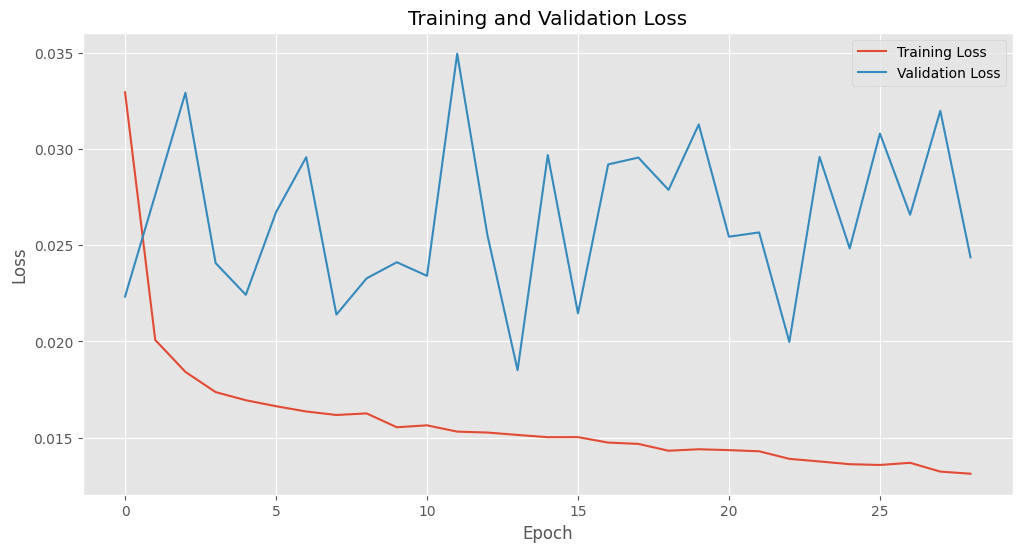


Evaluating model on test set...

Test Set Metrics:
RMSE: 71.0384
MAE: 56.2203
MAPE: 7.3003
MSE: 5046.4556
NRMSE: 8.8476


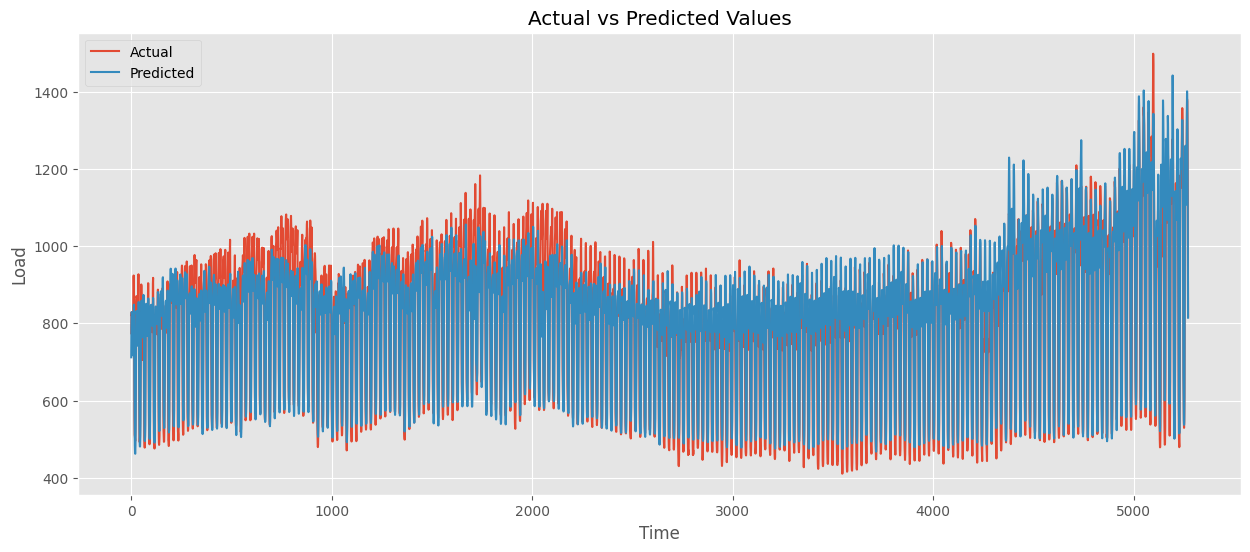

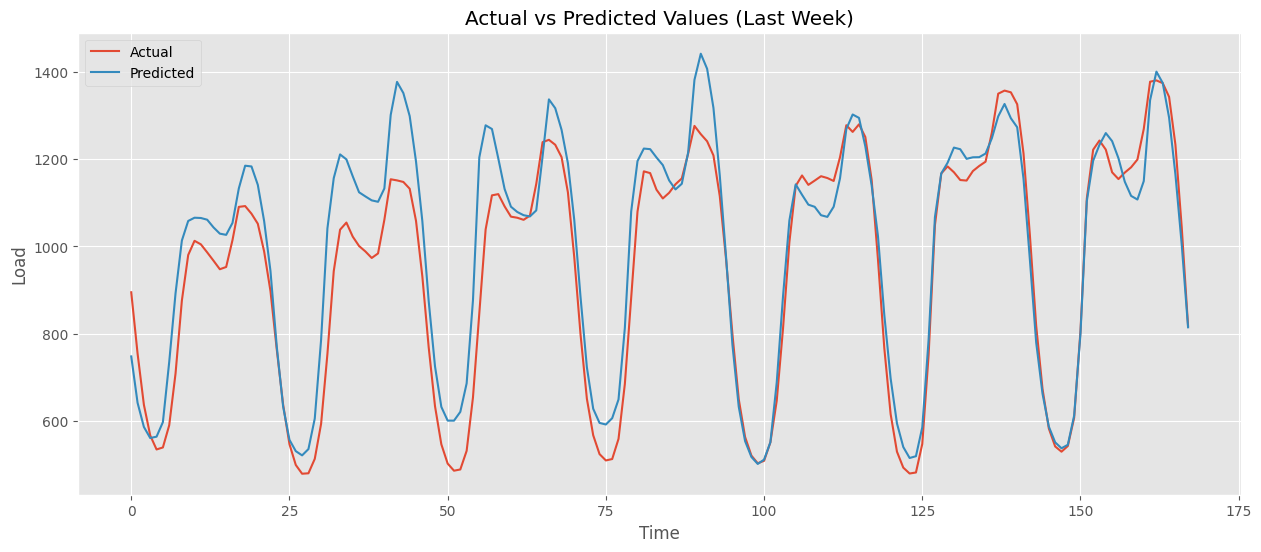

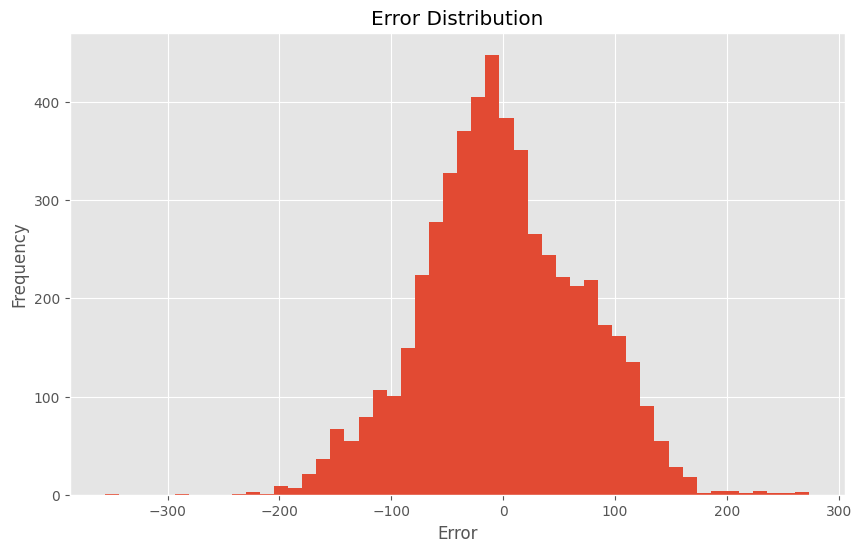


Completed Albania Load Forecasting with DAQLSTM and Optuna Hyperparameter Tuning


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import optuna
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import time
from datetime import datetime

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check if CUDA is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Custom Dataset for Time Series
class PowerDataset(Dataset):
    def __init__(self, features, targets):
        self.features = features
        self.targets = targets

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return torch.FloatTensor(self.features[idx]), torch.FloatTensor(self.targets[idx])

# Dual Attention Mechanism
class DualAttention(nn.Module):
    def __init__(self, hidden_dim):
        super(DualAttention, self).__init__()
        # Temporal attention
        self.temporal_attn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, lstm_output):
        # lstm_output shape: [batch, seq_len, hidden_dim]

        # Temporal Attention (across time steps)
        temp_attn = self.temporal_attn(lstm_output)  # [batch, seq_len, 1]
        temp_attn = torch.softmax(temp_attn, dim=1)
        temp_context = torch.bmm(temp_attn.transpose(1, 2), lstm_output)  # [batch, 1, hidden_dim]

        # Use average pooling for feature attention
        feat_context = lstm_output.mean(dim=1)  # [batch, hidden_dim]

        # Combine both attention outputs
        combined_context = temp_context.squeeze(1) + feat_context

        return combined_context

# QLSTM Model with Attention
class DAQLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, num_layers=2, dropout=0.25):
        super(DAQLSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # LSTM layer
        self.lstm = nn.LSTM(
            input_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        # Attention mechanism
        self.attention = DualAttention(hidden_dim)

        # Dropout layer
        self.dropout = nn.Dropout(dropout)

        # Output layer
        self.output_layer = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # x shape: [batch, seq_len, input_dim]

        # Pass through LSTM
        lstm_out, _ = self.lstm(x)  # [batch, seq_len, hidden_dim]

        # Apply attention
        attn_out = self.attention(lstm_out)

        # Apply dropout
        attn_out = self.dropout(attn_out)

        # Output layer
        output = self.output_layer(attn_out)

        return output

# Quantile Loss Function
def quantile_loss(preds, targets, quantile=0.6):
    errors = targets - preds
    return torch.mean(torch.max(quantile * errors, (quantile - 1) * errors))

# Function to create sequences for time series prediction
def create_sequences(X, y, seq_length):
    X_seq, y_seq = [], []
    for i in range(seq_length, len(X)):
        X_seq.append(X[i-seq_length:i, :])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

# Function to train the model
def train_model(model, train_loader, val_loader, optimizer, num_epochs, patience=10, quantile=0.6):
    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_state = None

    for epoch in range(num_epochs):
        start_time = time.time()

        # Training phase
        model.train()
        train_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            # Forward pass
            optimizer.zero_grad()
            outputs = model(X_batch)

            # Calculate loss
            loss = quantile_loss(outputs, y_batch, quantile)

            # Backward pass and optimize
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        train_loss /= len(train_loader)
        train_losses.append(train_loss)

        # Validation phase
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)

                outputs = model(X_batch)
                loss = quantile_loss(outputs, y_batch, quantile)

                val_loss += loss.item()

        val_loss /= len(val_loader)
        val_losses.append(val_loss)

        epoch_time = time.time() - start_time

        # Print progress
        print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}, Time: {epoch_time:.2f}s')

        # Check for improvement
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
            best_model_state = model.state_dict().copy()
        else:
            epochs_no_improve += 1

        # Early stopping
        if epochs_no_improve >= patience:
            print(f'Early stopping triggered after epoch {epoch+1}')
            break

    # Load best model
    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return model, train_losses, val_losses, best_val_loss

# Evaluate the model
def evaluate_model(model, test_loader, scaler_y):
    model.eval()
    predictions = []
    actuals = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            # Forward pass
            outputs = model(X_batch)

            # Store predictions and actuals
            predictions.extend(outputs.cpu().numpy())
            actuals.extend(y_batch.cpu().numpy())

    # Convert to numpy arrays and reshape
    predictions = np.array(predictions).reshape(-1, 1)
    actuals = np.array(actuals).reshape(-1, 1)

    # Inverse transform to original scale
    predictions = scaler_y.inverse_transform(predictions)
    actuals = scaler_y.inverse_transform(actuals)

    # Calculate metrics
    rmse = np.sqrt(mean_squared_error(actuals, predictions))
    mae = mean_absolute_error(actuals, predictions)
    mape = mean_absolute_percentage_error(actuals, predictions) * 100
    mse = mean_squared_error(actuals, predictions)
    nrmse = (rmse / np.mean(actuals)) * 100

    metrics = {
        'RMSE': rmse,
        'MAE': mae,
        'MAPE': mape,
        'MSE': mse,
        'NRMSE': nrmse
    }

    return predictions, actuals, metrics

# Optuna objective function for hyperparameter tuning
def objective(trial, X_train, y_train, X_val, y_val, input_dim):
    # Define hyperparameters to be tuned
    hidden_dim = trial.suggest_categorical('hidden_dim', [32, 64, 128, 256])
    num_layers = trial.suggest_int('num_layers', 1, 3)
    dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5, step=0.1)
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-1, log=True)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64, 128])
    seq_length = trial.suggest_categorical('seq_length', [12, 24, 48])
    quantile = trial.suggest_float('quantile', 0.5, 0.7, step=0.05)

    # Create sequences
    X_train_seq, y_train_seq = create_sequences(X_train, y_train, seq_length)
    X_val_seq, y_val_seq = create_sequences(X_val, y_val, seq_length)

    # Create datasets and dataloaders
    train_dataset = PowerDataset(X_train_seq, y_train_seq)
    val_dataset = PowerDataset(X_val_seq, y_val_seq)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    # Initialize model
    model = DAQLSTM(
        input_dim=input_dim,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        dropout=dropout_rate
    ).to(device)

    # Optimizer
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Train with early stopping
    _, _, _, best_val_loss = train_model(
        model,
        train_loader,
        val_loader,
        optimizer,
        num_epochs=30,  # Limit epochs for faster tuning
        patience=5,
        quantile=quantile
    )

    return best_val_loss

# Main execution
if __name__ == "__main__":
    print("Starting Albania Load Forecasting with DAQLSTM")

    # Load data
    print("Loading and preprocessing data...")
    df = pd.read_csv('/content/drive/MyDrive/thesis Final/Implementation/Albania_Dataset.csv')

    # Check for missing values
    missing_values = df.isnull().sum().sum()
    print(f"Missing values in dataset: {missing_values}")

    # Handle missing values if any
    if missing_values > 0:
        print("Filling missing values...")
        df = df.fillna(method='ffill').fillna(method='bfill')

    # Convert time column to datetime
    df['Time'] = pd.to_datetime(df['Time'])

    # Target variable is the Load column
    target_column = 'Load'

    # Drop non-numeric columns for modeling
    features_df = df.drop(['Time'], axis=1)

    # Print dataset info
    print(f"Dataset shape: {df.shape}")
    print(f"Date range: {df['Time'].min()} to {df['Time'].max()}")
    print(f"Number of features: {features_df.shape[1] - 1}")  # Excluding target

    # Scale data
    scaler_X = MinMaxScaler(feature_range=(0, 1))
    scaler_y = MinMaxScaler(feature_range=(0, 1))

    # Extract features and target
    X = features_df.drop([target_column], axis=1).values
    y = df[[target_column]].values

    # Scale features and target
    X_scaled = scaler_X.fit_transform(X)
    y_scaled = scaler_y.fit_transform(y)

    # Split data into train, validation, and test sets (70%, 15%, 15%)
    # We keep time order by not shuffling
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X_scaled, y_scaled, test_size=0.15, shuffle=False, random_state=42
    )

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val, y_train_val, test_size=0.176, shuffle=False, random_state=42
    )

    print(f"Train set shape: {X_train.shape}")
    print(f"Validation set shape: {X_val.shape}")
    print(f"Test set shape: {X_test.shape}")

    # Input dimension for the model
    input_dim = X_train.shape[1]

    # Hyperparameter tuning with Optuna
    print("\nStarting hyperparameter tuning with Optuna...")

    # Create a study object with Optuna
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))

    # Run hyperparameter optimization
    study.optimize(
        lambda trial: objective(trial, X_train, y_train, X_val, y_val, input_dim),
        n_trials=20,  # Adjust based on computational resources
        timeout=3600  # 1 hour timeout
    )

    # Get best trial and hyperparameters
    best_trial = study.best_trial
    best_params = best_trial.params

    print("\nBest trial:")
    print(f"  Value (Validation Loss): {best_trial.value}")
    print("  Params: ")
    for key, value in best_params.items():
        print(f"    {key}: {value}")

    # Plot optimization history
    plt.figure(figsize=(10, 6))
    optuna.visualization.matplotlib.plot_optimization_history(study)
    plt.title('Optimization History')
    plt.savefig('optuna_history.png')

    # Training with the best hyperparameters
    print("\nTraining final model with best hyperparameters...")

    # Get best hyperparameters
    best_hidden_dim = best_params['hidden_dim']
    best_num_layers = best_params['num_layers']
    best_dropout_rate = best_params['dropout_rate']
    best_learning_rate = best_params['learning_rate']
    best_batch_size = best_params['batch_size']
    best_seq_length = best_params['seq_length']
    best_quantile = best_params['quantile']

    # Create sequences with best sequence length
    X_train_seq, y_train_seq = create_sequences(X_train, y_train, best_seq_length)
    X_val_seq, y_val_seq = create_sequences(X_val, y_val, best_seq_length)
    X_test_seq, y_test_seq = create_sequences(X_test, y_test, best_seq_length)

    print(f"Sequence shapes after using window size {best_seq_length}:")
    print(f"  Train: {X_train_seq.shape}")
    print(f"  Validation: {X_val_seq.shape}")
    print(f"  Test: {X_test_seq.shape}")

    # Create datasets and dataloaders
    train_dataset = PowerDataset(X_train_seq, y_train_seq)
    val_dataset = PowerDataset(X_val_seq, y_val_seq)
    test_dataset = PowerDataset(X_test_seq, y_test_seq)

    train_loader = DataLoader(train_dataset, batch_size=best_batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=best_batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=best_batch_size, shuffle=False)

    # Initialize final model with best hyperparameters
    final_model = DAQLSTM(
        input_dim=input_dim,
        hidden_dim=best_hidden_dim,
        num_layers=best_num_layers,
        dropout=best_dropout_rate
    ).to(device)

    # Optimizer
    optimizer = optim.Adam(final_model.parameters(), lr=best_learning_rate)

    # Train final model
    final_model, train_losses, val_losses, _ = train_model(
        final_model,
        train_loader,
        val_loader,
        optimizer,
        num_epochs=100,
        patience=15,
        quantile=best_quantile
    )

    # Save the model
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    model_filename = f"daqlstm_albania_load_{timestamp}.pth"

    torch.save({
        'model_state_dict': final_model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'hyperparameters': best_params,
        'scaler_X': scaler_X,
        'scaler_y': scaler_y
    }, model_filename)

    print(f"Model saved to {model_filename}")

    # Plot training and validation loss
    plt.figure(figsize=(12, 6))
    plt.plot(train_losses, label='Training Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.savefig(f'training_loss_{timestamp}.png')
    plt.show()

    # Evaluate on test set
    print("\nEvaluating model on test set...")
    predictions, actuals, metrics = evaluate_model(final_model, test_loader, scaler_y)

    # Print metrics
    print("\nTest Set Metrics:")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

    # Plot actual vs predicted values for the test set
    plt.figure(figsize=(15, 6))
    plt.plot(actuals, label='Actual')
    plt.plot(predictions, label='Predicted')
    plt.title('Actual vs Predicted Values')
    plt.xlabel('Time')
    plt.ylabel('Load')
    plt.legend()
    plt.grid(True)
    plt.savefig(f'predictions_{timestamp}.png')
    plt.show()

    # Plot a subset of the predictions (last week) for better visibility
    plt.figure(figsize=(15, 6))
    subset_size = min(168, len(predictions))  # 168 hours = 1 week
    plt.plot(actuals[-subset_size:], label='Actual')
    plt.plot(predictions[-subset_size:], label='Predicted')
    plt.title('Actual vs Predicted Values (Last Week)')
    plt.xlabel('Time')
    plt.ylabel('Load')
    plt.legend()
    plt.grid(True)
    plt.savefig(f'predictions_lastweek_{timestamp}.png')
    plt.show()

    # Plot error distribution
    errors = actuals.flatten() - predictions.flatten()
    plt.figure(figsize=(10, 6))
    plt.hist(errors, bins=50)
    plt.title('Error Distribution')
    plt.xlabel('Error')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.savefig(f'error_distribution_{timestamp}.png')
    plt.show()

    print("\nCompleted Albania Load Forecasting with DAQLSTM and Optuna Hyperparameter Tuning")